In [7]:
import numpy as np
import pandas as pd
from scipy.fft import dct, idct, dst, idst
from sympy import prime
import matplotlib.pyplot as plt
from struct import unpack, pack, calcsize
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim

In [8]:
MAX_LEN_CHUNK = 0xFF  ##########
PATH = "0xff.bin"  ##########
f = open(PATH, "rb")
buf = f.read(MAX_LEN_CHUNK)
f.close()
lenbuf = len(buf)
x = unpack("B" * lenbuf, buf)
x = np.array(x)
x

array([255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255,
       255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 255, 25

In [9]:
coef = dct(x)
coef

array([ 1.30050000e+05,  0.00000000e+00,  0.00000000e+00, -7.23240330e-12,
        0.00000000e+00,  0.00000000e+00, -2.92606821e-12,  0.00000000e+00,
        0.00000000e+00, -1.95126746e-12,  0.00000000e+00,  0.00000000e+00,
       -1.80964549e-12,  0.00000000e+00,  0.00000000e+00,  3.62245983e-12,
        0.00000000e+00,  0.00000000e+00,  1.20780528e-12,  0.00000000e+00,
        0.00000000e+00,  8.38164841e-13,  0.00000000e+00,  0.00000000e+00,
        7.34021462e-13,  0.00000000e+00,  0.00000000e+00,  8.07271302e-13,
        0.00000000e+00,  0.00000000e+00,  7.15207061e-12,  0.00000000e+00,
        0.00000000e+00, -6.62003657e-13,  0.00000000e+00,  0.00000000e+00,
       -4.91586262e-13,  0.00000000e+00,  0.00000000e+00, -4.54420406e-13,
        0.00000000e+00,  0.00000000e+00, -5.22378996e-13,  0.00000000e+00,
        0.00000000e+00,  3.49910131e-12,  0.00000000e+00,  0.00000000e+00,
        4.58653383e-13,  0.00000000e+00,  0.00000000e+00,  3.49892109e-13,
        0.00000000e+00,  

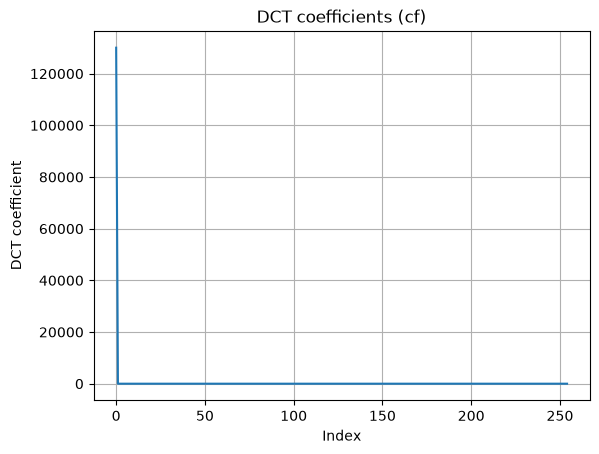

In [10]:
plt.plot(coef)
plt.xlabel("Index")
plt.ylabel("DCT coefficient")
plt.title("DCT coefficients (cf)")
plt.grid(True)
plt.show()

In [ ]:
fc = "<f"
coef_reconstructed = np.zeros_like(coef)
coef_reconstructed[0] = unpack(fc, pack(fc, coef[0]))[0]
reconstructed = np.rint(idct(coef_reconstructed)).astype(int)
if np.all(reconstructed == x):
    savedbuf = pack(fc, coef[0])
    savedbuf = pack("B", len(savedbuf)) + savedbuf
    print(savedbuf)
else:
    print("fluctuant")

b'\x04\x00\x01\xfeG'
